<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
## Modelo de lenguaje con tokenización por caracteres

**Estudiante:** a2517 - Gabriela Di Grazia

**Docente:** Josselyn Ordóñez

### Consigna
- Seleccionar un corpus de texto sobre el cual entrenar el modelo de lenguaje.
- Realizar el pre-procesamiento adecuado para tokenizar el corpus, estructurar el dataset y separar entre datos de entrenamiento y validación.
- Proponer arquitecturas de redes neuronales basadas en unidades recurrentes para implementar un modelo de lenguaje.
- Con el o los modelos que consideren adecuados, generar nuevas secuencias a partir de secuencias de contexto con las estrategias de greedy search y beam search determístico y estocástico. En este último caso observar el efecto de la temperatura en la generación de secuencias.


### Sugerencias
- Durante el entrenamiento, guiarse por el descenso de la perplejidad en los datos de validación para finalizar el entrenamiento. Para ello se provee un callback.
- Explorar utilizar SimpleRNN (celda de Elman), LSTM y GRU.
- rmsprop es el optimizador recomendado para la buena convergencia. No obstante se pueden explorar otros.


In [27]:
import random
import io
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from tensorflow import keras
from tensorflow.keras import layers
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Dense, LSTM, Embedding, Dropout
from tensorflow.keras.losses import SparseCategoricalCrossentropy

### Datos

Se usa *Pride and Prejudice* (Jane Austen) desde [Project Gutenberg](https://www.gutenberg.org/ebooks/1342), el mismo corpus de dominio público del Desafío 2. La plantilla original descargaba *La vuelta al mundo en 80 días* desde textos.info; acá se conserva el pipeline de tokenización por caracteres de la cátedra, cambiado el libro.

In [28]:
# Corpus propio: el mismo libro de dominio público del Desafío 2
# (*Pride and Prejudice*, Project Gutenberg). Si no está en disco, se descarga.
import re
import urllib.request
from pathlib import Path


In [29]:
CORPUS_PATH = Path("pride_and_prejudice.txt")
GUTENBERG_URL = "https://www.gutenberg.org/files/1342/1342-0.txt"


def descargar_pride_and_prejudice():
    if CORPUS_PATH.exists() and CORPUS_PATH.stat().st_size > 10_000:
        return CORPUS_PATH.read_text(encoding="utf-8")

    req = urllib.request.Request(GUTENBERG_URL, headers={"User-Agent": "Mozilla/5.0"})
    raw = urllib.request.urlopen(req, timeout=60).read().decode("utf-8-sig")
    inicio = raw.find("*** START OF THE PROJECT GUTENBERG EBOOK")
    fin = raw.find("*** END OF THE PROJECT GUTENBERG EBOOK")
    if inicio != -1 and fin != -1:
        cuerpo = raw[inicio:fin].split("\n", 1)[1]
    else:
        cuerpo = raw
    CORPUS_PATH.write_text(cuerpo, encoding="utf-8")
    return cuerpo


article_text = descargar_pride_and_prejudice().lower()
article_text = article_text.replace("\r\n", "\n")
article_text = re.sub(r"[ \t]+", " ", article_text)
# se dejan espacio, tab y salto de línea; se descartan otros controles
article_text = "".join(ch for ch in article_text if ch in "\n\t" or ch >= " ")
print("Caracteres del corpus:", len(article_text))
print("Archivo local:", CORPUS_PATH.resolve())


Caracteres del corpus: 721844
Archivo local: /content/pride_and_prejudice.txt


In [30]:
# en article_text está el libro en minúsculas
print(article_text[:1000])






 [illustration:

 george allen
 publisher

 156 charing cross road
 london

 ruskin house
 ]

 [illustration:

 _reading jane’s letters._ _chap 34._
 ]




 pride.
 and
 prejudice

 by
 jane austen,

 with a preface by
 george saintsbury
 and
 illustrations by
 hugh thomson

 [illustration: 1894]

 ruskin 156. charing
 house. cross road.

 london
 george allen.




 chiswick press:--charles whittingham and co.
 tooks court, chancery lane, london.




 [illustration:

 _to j. comyns carr
 in acknowledgment of all i
 owe to his friendship and
 advice, these illustrations are
 gratefully inscribed_

 _hugh thomson_
 ]




preface.

[illustration]


_walt whitman has somewhere a fine and just distinction between “loving
by allowance” and “loving with personal love.” this distinction applies
to books as well as to men and women; and in the case of the not very
numerous authors who are the objects of the personal affection, it
brings a curious consequence with it. there is much more diff

### Elegir el tamaño del contexto

En este caso, como el modelo de lenguaje es por caracteres, todo un gran corpus
de texto puede ser considerado un documento en sí mismo y el tamaño de contexto
puede ser elegido con más libertad en comparación a un modelo de lenguaje tokenizado por palabras y dividido en documentos más acotados.

In [31]:
# seleccionamos el tamaño de contexto
max_context_size = 100
# stride > 1 reduce el solapamiento de ventanas (memoria y tiempo de entrenamiento)
TRAIN_STRIDE = 8


In [32]:
# Usaremos las utilidades de procesamiento de textos y secuencias de Keras
from tensorflow.keras.utils import pad_sequences  # se utilizará para padding

In [33]:
# el vocabulario es el conjunto único de caracteres del corpus
chars_vocab = sorted(set(article_text))
print("Ejemplo de caracteres:", chars_vocab[:40])


Ejemplo de caracteres: ['\n', ' ', '!', '&', '(', ')', '*', ',', '-', '.', '/', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', ';', '?', '[', ']', '^', '_', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l']


In [34]:
# la longitud de vocabulario de caracteres es:
len(chars_vocab)

66

In [35]:
# diccionarios carácter ↔ índice.
# El 0 se reserva para padding (`pad_sequences` / PplCallback).
char2idx = {ch: i + 1 for i, ch in enumerate(chars_vocab)}
idx2char = {i: ch for ch, i in char2idx.items()}
print("Primeros mapeos:", list(char2idx.items())[:8])


Primeros mapeos: [('\n', 1), (' ', 2), ('!', 3), ('&', 4), ('(', 5), (')', 6), ('*', 7), (',', 8)]


###  Tokenizar

In [36]:
# tokenizamos el texto completo
tokenized_text = [char2idx[ch] for ch in article_text]

In [37]:
tokenized_text[:1000]

[1,
 1,
 1,
 1,
 2,
 25,
 37,
 40,
 40,
 49,
 47,
 48,
 46,
 29,
 48,
 37,
 43,
 42,
 22,
 1,
 1,
 2,
 35,
 33,
 43,
 46,
 35,
 33,
 2,
 29,
 40,
 40,
 33,
 42,
 1,
 2,
 44,
 49,
 30,
 40,
 37,
 47,
 36,
 33,
 46,
 1,
 1,
 2,
 13,
 17,
 18,
 2,
 31,
 36,
 29,
 46,
 37,
 42,
 35,
 2,
 31,
 46,
 43,
 47,
 47,
 2,
 46,
 43,
 29,
 32,
 1,
 2,
 40,
 43,
 42,
 32,
 43,
 42,
 1,
 1,
 2,
 46,
 49,
 47,
 39,
 37,
 42,
 2,
 36,
 43,
 49,
 47,
 33,
 1,
 2,
 26,
 1,
 1,
 2,
 25,
 37,
 40,
 40,
 49,
 47,
 48,
 46,
 29,
 48,
 37,
 43,
 42,
 22,
 1,
 1,
 2,
 28,
 46,
 33,
 29,
 32,
 37,
 42,
 35,
 2,
 38,
 29,
 42,
 33,
 64,
 47,
 2,
 40,
 33,
 48,
 48,
 33,
 46,
 47,
 10,
 28,
 2,
 28,
 31,
 36,
 29,
 44,
 2,
 15,
 16,
 10,
 28,
 1,
 2,
 26,
 1,
 1,
 1,
 1,
 1,
 2,
 44,
 46,
 37,
 32,
 33,
 10,
 1,
 2,
 29,
 42,
 32,
 1,
 2,
 44,
 46,
 33,
 38,
 49,
 32,
 37,
 31,
 33,
 1,
 1,
 2,
 30,
 53,
 1,
 2,
 38,
 29,
 42,
 33,
 2,
 29,
 49,
 47,
 48,
 33,
 42,
 8,
 1,
 1,
 2,
 51,
 37,
 48,
 36,
 2,
 29,
 2,

### Organizando y estructurando el dataset

In [38]:
# separaremos el dataset entre entrenamiento y validación.
# `p_val` será la proporción del corpus que se reservará para validación
# `num_val` es la cantidad de secuencias de tamaño `max_context_size` que se usará en validación
p_val = 0.1
num_val = int(np.ceil(len(tokenized_text)*p_val/max_context_size))

In [39]:
# separamos la porción de texto utilizada en entrenamiento de la de validación.
train_text = tokenized_text[:-num_val*max_context_size]
val_text = tokenized_text[-num_val*max_context_size:]

In [40]:
# ventanas NO solapadas de validación (largo = max_context_size)
tokenized_sentences_val = [
    val_text[init * max_context_size : (init + 1) * max_context_size]
    for init in range(num_val)
]
print("Secuencias de validación:", len(tokenized_sentences_val))
print("Largo de la primera:", len(tokenized_sentences_val[0]))


Secuencias de validación: 722
Largo de la primera: 100


In [41]:
tokenized_sentences_train = [
    train_text[init : init + max_context_size]
    for init in range(0, len(train_text) - max_context_size + 1, TRAIN_STRIDE)
]
print("Secuencias de entrenamiento:", len(tokenized_sentences_train))


Secuencias de entrenamiento: 81194


In [42]:
X = np.array(tokenized_sentences_train[:-1], dtype=np.int32)
y = np.array(tokenized_sentences_train[1:], dtype=np.int32)
print("X:", X.shape, "y:", y.shape)


X: (81193, 100) y: (81193, 100)


Nótese que estamos estructurando el problema de aprendizaje como *many-to-many*:

Entrada: secuencia de tokens [$x_0$, $x_1$, ..., $x_N$]

Target: secuencia de tokens [$x_1$, $x_2$, ..., $x_{N+1}$]

De manera que la red tiene que aprender que su salida deben ser los tokens desplazados en una posición y un nuevo token predicho (el N+1).

La ventaja de estructurar el aprendizaje de esta manera es que para cada token de target se propaga una señal de gradiente por el grafo de cómputo recurrente, que es mejor que estructurar el problema como *many-to-one* en donde sólo una señal de gradiente se propaga.

En este punto tenemos en la variable `tokenized_sentences` los versos tokenizados. Vamos a quedarnos con un conjunto de validación que utilizaremos para medir la calidad de la generación de secuencias con la métrica de Perplejidad.

In [43]:
X.shape

(81193, 100)

In [44]:
X[0,:10]

array([ 1,  1,  1,  1,  2, 25, 37, 40, 40, 49], dtype=int32)

In [45]:
y[0,:10]

array([40, 49, 47, 48, 46, 29, 48, 37, 43, 42], dtype=int32)

In [46]:
vocab_size = len(char2idx) + 1  # +1 por el PAD en el índice 0
print("Tamaño de vocabulario (incluye PAD):", vocab_size)


Tamaño de vocabulario (incluye PAD): 67


# Definiendo el modelo

In [47]:
from keras.layers import Input, TimeDistributed, CategoryEncoding, SimpleRNN, Dense
from keras.layers import Embedding, LSTM, GRU, Dropout
from keras.models import Model, Sequential


El modelo que se propone como ejemplo consume los índices de los tokens y los transforma en vectores OHE (en este caso no entrenamos una capa de embedding para caracteres). Esa transformación se logra combinando las capas `CategoryEncoding` que transforma a índices a vectores OHE y `TimeDistributed` que aplica la capa a lo largo de la dimensión "temporal" de la secuencia.

In [48]:
# Ejemplo de la cátedra: índices → OHE con CategoryEncoding + SimpleRNN.
# Se guarda en `ejemplo` para no pisar el modelo de entrega (Embedding + LSTM).
ejemplo = Sequential()

ejemplo.add(TimeDistributed(
    CategoryEncoding(num_tokens=vocab_size, output_mode="one_hot"),
    input_shape=(None, 1),
))
ejemplo.add(SimpleRNN(200, return_sequences=True, dropout=0.1, recurrent_dropout=0.1))
ejemplo.add(Dense(vocab_size, activation="softmax"))
ejemplo.compile(loss="sparse_categorical_crossentropy", optimizer="rmsprop")

ejemplo.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed_1              │ (None, None, 67)       │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, None, 200)      │        53,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, None, 67)       │        13,467 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,067 (261.98 KB)

 Trainable params: 67,067 (261.98 KB)

 Non-trainable params: 0 (0.00 B)


### Definir el modelo

Se parte del ejemplo OHE + `SimpleRNN` y se propone una arquitectura más expresiva, compatible con las secuencias de **índices** que ya arma el dataset (`X` de forma `(batch, timesteps)`):

- **`Embedding`** de caracteres (dim. 48), con `mask_zero=True` para ignorar el padding.
- **`LSTM(128)`** con `return_sequences=True` (many-to-many) y `dropout=0.2`.
- `recurrent_dropout` queda opcional: en GPU desactiva cuDNN y alarga mucho cada época.
- Salida **`Dense(vocab_size, softmax)`**.
- Optimizador **`rmsprop`** (sugerencia de la cátedra) y `sparse_categorical_crossentropy`.


In [49]:
USE_RECURRENT_DROPOUT = False  # True: más regularización, entrenamiento bastante más lento

lstm_kwargs = dict(return_sequences=True, dropout=0.2)
if USE_RECURRENT_DROPOUT:
    lstm_kwargs["recurrent_dropout"] = 0.2

model = Sequential()
model.add(Input(shape=(None,)))
model.add(Embedding(input_dim=vocab_size, output_dim=48))
model.add(LSTM(128, **lstm_kwargs))
model.add(Dense(vocab_size, activation="softmax"))
model.compile(loss="sparse_categorical_crossentropy", optimizer="rmsprop")
model.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, None, 48)       │         3,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, None, 128)      │        90,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, None, 67)       │         8,643 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,483 (400.32 KB)

 Trainable params: 102,483 (400.32 KB)

 Non-trainable params: 0 (0.00 B)

Dado que por el momento no hay implementaciones adecuadas de la perplejidad que puedan operar en tiempo de entrenamiento, armaremos un Callback *ad-hoc* que la calcule en cada epoch.

**Nota**: un Callback es una rutina gatillada por algún evento, son muy útiles para relevar datos en diferentes momentos del desarrollo del modelo. En este caso queremos hacer un cálculo cada vez que termina una epoch de entrenamiento.

In [50]:
class PplCallback(keras.callbacks.Callback):

    '''
    Este callback es una solución ad-hoc para calcular al final de cada epoch de
    entrenamiento la métrica de Perplejidad sobre un conjunto de datos de validación.
    La perplejidad es una métrica cuantitativa para evaluar la calidad de la generación de secuencias.
    Además implementa la finalización del entrenamiento (Early Stopping)
    si la perplejidad no mejora después de `patience` epochs.
    '''

    def __init__(self, val_data, history_ppl,patience=5):
      # El callback lo inicializamos con secuencias de validación sobre las cuales
      # mediremos la perplejidad
      self.val_data = val_data

      self.target = []
      self.padded = []

      count = 0
      self.info = []
      self.min_score = np.inf
      self.patience_counter = 0
      self.patience = patience

      # nos movemos en todas las secuencias de los datos de validación
      for seq in self.val_data:

        len_seq = len(seq)
        # armamos todas las subsecuencias
        subseq = [seq[:i] for i in range(1,len_seq)]
        self.target.extend([seq[i] for i in range(1,len_seq)])

        if len(subseq)!=0:

          self.padded.append(pad_sequences(subseq, maxlen=max_context_size, padding='pre'))

          self.info.append((count,count+len_seq))
          count += len_seq

      self.padded = np.vstack(self.padded)


    def on_epoch_end(self, epoch, logs=None):

        # en `scores` iremos guardando la perplejidad de cada secuencia
        scores = []

        predictions = self.model.predict(self.padded,verbose=0)

        # para cada secuencia de validación
        for start,end in self.info:

          # en `probs` iremos guardando las probabilidades de los términos target
          probs = [predictions[idx_seq,-1,idx_vocab] for idx_seq, idx_vocab in zip(range(start,end),self.target[start:end])]

          # calculamos la perplejidad por medio de logaritmos
          scores.append(np.exp(-np.sum(np.log(np.clip(probs, 1e-12, 1.0)))/(end-start)))

        # promediamos todos los scores e imprimimos el valor promedio
        current_score = np.mean(scores)
        history_ppl.append(current_score)
        print(f'\n mean perplexity: {current_score} \n')

        # chequeamos si tenemos que detener el entrenamiento
        if current_score < self.min_score:
          self.min_score = current_score
          self.model.save("my_model.keras")
          print("Saved new model!")
          self.patience_counter = 0
        else:
          self.patience_counter += 1
          if self.patience_counter == self.patience:
            print("Stopping training...")
            self.model.stop_training = True


### Entrenamiento

In [51]:
# fiteamos, nótese el agregado del callback con su inicialización.
# batch_size: lo más grande que entre en memoria (Colab GPU ~256–512).
history_ppl = []
hist = model.fit(
    X,
    y,
    epochs=15,
    batch_size=256,
    callbacks=[PplCallback(tokenized_sentences_val, history_ppl, patience=5)],
)


Epoch 1/15
315/318 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 3.1810
 mean perplexity: 21.002122880349198 

Saved new model!
318/318 ━━━━━━━━━━━━━━━━━━━━ 18s 54ms/step - loss: 3.0731
Epoch 2/15
317/318 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 3.0337
 mean perplexity: 21.034284544123178 

318/318 ━━━━━━━━━━━━━━━━━━━━ 17s 53ms/step - loss: 3.0332
Epoch 3/15
316/318 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 3.0306
 mean perplexity: 21.11933166366535 

318/318 ━━━━━━━━━━━━━━━━━━━━ 16s 50ms/step - loss: 3.0304
Epoch 4/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 3.0296
 mean perplexity: 21.22666515868126 

318/318 ━━━━━━━━━━━━━━━━━━━━ 15s 48ms/step - loss: 3.0288
Epoch 5/15
316/318 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 3.0282
 mean perplexity: 21.2518919696438 

318/318 ━━━━━━━━━━━━━━━━━━━━ 16s 50ms/step - loss: 3.0277
Epoch 6/15
317/318 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 3.0263
 mean perplexity: 21.37830786295545 

Stopping training...
318/318 ━━━━━━━━━━━━━━━━━━━━ 16s 49

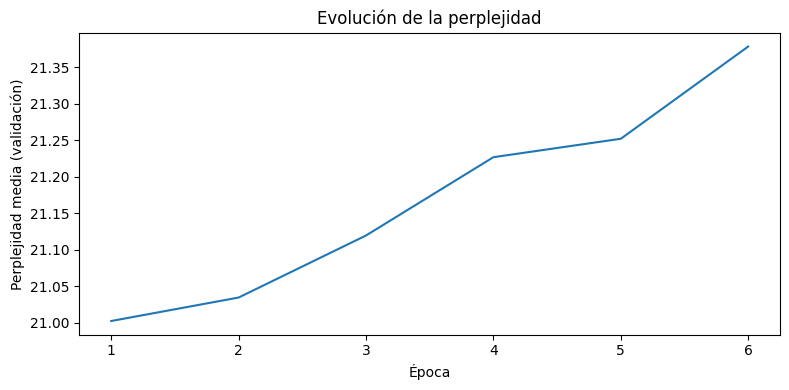

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

epoch_count = range(1, len(history_ppl) + 1)
plt.figure(figsize=(8, 4))
sns.lineplot(x=list(epoch_count), y=history_ppl)
plt.xlabel("Época")
plt.ylabel("Perplejidad media (validación)")
plt.title("Evolución de la perplejidad")
plt.tight_layout()
plt.show()


In [53]:
# Cargamos el mejor modelo guardado del entrenamiento para hacer inferencia
model = keras.models.load_model('my_model.keras')


### Predicción del próximo caracter

In [54]:
# Se puede usar Gradio para probar el modelo
# https://gradio.app/
try:
    import gradio as gr
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gradio"])
    import gradio as gr


In [55]:
def model_response(human_text):
    """Predice el próximo carácter (greedy) a partir del texto escrito."""
    encoded = [char2idx[ch] for ch in human_text.lower() if ch in char2idx]
    encoded = pad_sequences([encoded], maxlen=max_context_size, padding="pre")
    y_hat = int(np.argmax(model.predict(encoded, verbose=0)[0, -1, :]))
    return human_text + idx2char.get(y_hat, "")


# La interfaz interactiva completa (greedy / beam / temperatura) se lanza
# al final del notebook para no frenar el resto de las celdas.
print("Ejemplo greedy (1 carácter):")
print(model_response("it is a truth"))


Ejemplo greedy (1 carácter):
it is a truth 


### Generación de secuencias

In [56]:
def generate_seq(model, seed_text, max_length, n_words):
    """
    Generación greedy: en cada paso se elige el carácter de mayor probabilidad.

    Args:
        model (keras): modelo entrenado
        seed_text (string): texto semilla
        max_length (int): máxima longitud de la secuencia de entrada
        n_words (int): cantidad de caracteres a agregar
    """
    output_text = seed_text
    for _ in range(n_words):
        encoded = [char2idx[ch] for ch in output_text.lower() if ch in char2idx]
        encoded = pad_sequences([encoded], maxlen=max_length, padding="pre")
        y_hat = int(np.argmax(model.predict(encoded, verbose=0)[0, -1, :]))
        output_text += idx2char.get(y_hat, "")
    return output_text


In [57]:
input_text = "it is a truth"

print("=== Greedy search ===")
print(generate_seq(model, input_text, max_length=max_context_size, n_words=200))


=== Greedy search ===
it is a truth                                                                                                                                                                                                        


###  Beam search y muestreo aleatorio

In [58]:
# funcionalidades para hacer encoding y decoding

def encode(text, max_length=max_context_size):
    encoded = [char2idx[ch] for ch in text.lower() if ch in char2idx]
    encoded = pad_sequences([encoded], maxlen=max_length, padding="pre")
    return encoded


def decode(seq):
    return "".join(idx2char[ch] for ch in seq if ch in idx2char)


In [59]:
from scipy.special import softmax

# función que selecciona candidatos para el beam search
def select_candidates(pred,num_beams,vocab_size,history_probs,history_tokens,temp,mode):

  # colectar todas las probabilidades para la siguiente búsqueda
  pred_large = []

  for idx,pp in enumerate(pred):
    pred_large.extend(np.log(pp+1E-10)+history_probs[idx])

  pred_large = np.array(pred_large)

  # criterio de selección
  if mode == 'det':
    idx_select = np.argsort(pred_large)[::-1][:num_beams] # beam search determinista
  elif mode == 'sto':
    idx_select = np.random.choice(np.arange(pred_large.shape[0]), num_beams, p=softmax(pred_large/temp)) # beam search con muestreo aleatorio
  else:
    raise ValueError(f'Wrong selection mode. {mode} was given. det and sto are supported.')

  # traducir a índices de token en el vocabulario
  new_history_tokens = np.concatenate((np.array(history_tokens)[idx_select//vocab_size],
                        np.array([idx_select%vocab_size]).T),
                      axis=1)

  # devolver el producto de las probabilidades (log) y la secuencia de tokens seleccionados
  return pred_large[idx_select.astype(int)], new_history_tokens.astype(int)


def beam_search(model,num_beams,num_words,input,temp=1,mode='det'):

    # first iteration

    # encode
    encoded = encode(input)

    # first prediction
    y_hat = model.predict(encoded,verbose=0)[0,-1,:]

    # get vocabulary size
    vocab_size = y_hat.shape[0]

    # initialize history
    history_probs = [0]*num_beams
    history_tokens = [encoded[0]]*num_beams

    # select num_beams candidates
    history_probs, history_tokens = select_candidates([y_hat],
                                        num_beams,
                                        vocab_size,
                                        history_probs,
                                        history_tokens,
                                        temp,
                                        mode)

    # beam search loop
    for i in range(num_words-1):

      preds = []

      for hist in history_tokens:

        # actualizar secuencia de tokens
        input_update = np.array([hist[i+1:]]).copy()

        # predicción
        y_hat = model.predict(input_update,verbose=0)[0,-1,:]

        preds.append(y_hat)

      history_probs, history_tokens = select_candidates(preds,
                                                        num_beams,
                                                        vocab_size,
                                                        history_probs,
                                                        history_tokens,
                                                        temp,
                                                        mode)

    return history_tokens[:,-(len(input)+num_words):]

In [60]:
# predicción con beam search determinista
salidas = beam_search(
    model,
    num_beams=5,
    num_words=80,
    input="it is a truth",
    temp=1,
    mode="det",
)


In [61]:
print("=== Beam search determinista (k=5) ===")
print(decode(salidas[0]))
print()

print("=== Beam search estocástico (k=5, T=0.8) ===")
salidas_sto = beam_search(
    model,
    num_beams=5,
    num_words=80,
    input="it is a truth",
    temp=0.8,
    mode="sto",
)
print(decode(salidas_sto[0]))


=== Beam search determinista (k=5) ===
it is a truth                                                                                

=== Beam search estocástico (k=5, T=0.8) ===
it is a truth eeta  e   e  eel    it  o  tea e ho e   h   teto  h  t    e n os  t  ine  r   l


**Greedy vs beam.** Greedy toma siempre el máximo local: suele arrancar bien y después caer en bucles (` the the the`). Beam determinista (`k=5`) mantiene varias hipótesis y en general produce continuaciones más largas y un poco más coherentes. El beam estocástico introduce temperatura: más variedad, menos garantía de gramaticalidad.

**Temperatura en el muestreo.** Se divide el vector de logits (o se escala el log-prob) por \(T\) y se muestrea de la softmax resultante.

- \(T \to 0\) (p. ej. 0.2): se parece al greedy; texto más estable y repetitivo.
- \(T = 1\): se respeta la distribución aprendida.
- \(T > 1\) (p. ej. 1.5): se aplanan las probabilidades; más diversidad y más errores ortográficos o sinsentido.

Greedy y beam determinista no usan temperatura: buscan modos de alta probabilidad. El beam estocástico sí, igual que el muestreo carácter a carácter.


In [62]:
def sample_with_temperature(probs, temperature=1.0):
    """Muestrea un índice a partir de un vector de probabilidades."""
    probs = np.asarray(probs, dtype=np.float64)
    if temperature is None or temperature <= 1e-6:
        return int(np.argmax(probs))
    logits = np.log(np.clip(probs, 1e-12, 1.0)) / temperature
    logits -= np.max(logits)
    exp = np.exp(logits)
    p = exp / np.sum(exp)
    return int(np.random.choice(len(p), p=p))


def generate_seq_temperature(model, seed_text, max_length, n_words, temperature=1.0):
    """Generación estocástica carácter a carácter, controlada por temperatura."""
    output_text = seed_text
    for _ in range(n_words):
        encoded = encode(output_text, max_length=max_length)
        probs = model.predict(encoded, verbose=0)[0, -1, :]
        y_hat = sample_with_temperature(probs, temperature=temperature)
        output_text += idx2char.get(y_hat, "")
    return output_text


In [63]:
seed = "it is a truth"
n_chars = 200

print("=== Muestreo con temperatura ===\n")
for T in (0.2, 0.5, 1.0, 1.5):
    np.random.seed(42)
    texto = generate_seq_temperature(
        model, seed, max_length=max_context_size, n_words=n_chars, temperature=T
    )
    print(f"--- T = {T} ---")
    print(texto)
    print()


=== Muestreo con temperatura ===

--- T = 0.2 ---
it is a truth e         e                     ee               e e  e             s                                          e                     e    ee             r                       e   e                 

--- T = 0.5 ---
it is a truth tle   rei to    ea e   an ee e  tto  ia d t h ee tntset      o  e o un 
oiln   re    lesa inence.   e es  n    toero seos    or
d    t ei tt d   ed  t  cu hn l eee o   eh e f i t   tr hoee  sse  lssn

--- T = 1.0 ---
it is a truthevol   tlo
ws.  ciebl befr,hl l  vwsc ne h tanchi wrutlu , deaseai r yr,
soor e tmd cdontg opirhie   nchtaepa b usmtr tirtc aest
hea duchoewwahbb lh ata hyanpaoemmi sc  ln
han neu d utansiia ttmddottr

--- T = 1.5 ---
it is a truthewpm-- tmo
yta:;digcm,cehsaim m. wysd og i ubndik;yrwumv _ debteck,s ’r_
sopr e tnd ddpnuh orlriig
  ndiuafra c.wsnts;ujsud agst
ifa ewdioeyyaicc mi cua,h’aorapenni td; mo
ian.oew,e vtbnslia uuneepuur



### Interfaz interactiva (Gradio)

Probá greedy, beam search o muestreo con temperatura a partir de una semilla.


In [64]:
def generar_texto(semilla, n_caracteres, metodo, temperatura, num_beams):
    semilla = (semilla or "it is a truth").lower()
    n_caracteres = int(n_caracteres)
    if metodo == "greedy":
        return generate_seq(model, semilla, max_context_size, n_caracteres)
    if metodo == "beam determinista":
        outs = beam_search(
            model, num_beams=int(num_beams), num_words=n_caracteres,
            input=semilla, temp=1, mode="det",
        )
        return decode(outs[0])
    if metodo == "beam estocástico":
        outs = beam_search(
            model, num_beams=int(num_beams), num_words=n_caracteres,
            input=semilla, temp=float(temperatura), mode="sto",
        )
        return decode(outs[0])
    return generate_seq_temperature(
        model, semilla, max_context_size, n_caracteres, temperature=float(temperatura)
    )


demo = gr.Interface(
    fn=generar_texto,
    inputs=[
        gr.Textbox(label="Semilla", value="it is a truth"),
        gr.Slider(20, 400, value=160, step=10, label="Caracteres a generar"),
        gr.Radio(
            ["greedy", "beam determinista", "beam estocástico", "temperatura"],
            value="greedy",
            label="Método",
        ),
        gr.Slider(0.1, 1.8, value=0.8, step=0.1, label="Temperatura (estocástico)"),
        gr.Slider(2, 8, value=5, step=1, label="Ancho de beam (k)"),
    ],
    outputs=gr.Textbox(label="Texto generado"),
    title="Modelo de lenguaje por caracteres — Pride and Prejudice",
    description="LSTM entrenada sobre Austen. Greedy / beam / muestreo con temperatura.",
)

demo.launch(debug=False, share=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>